# LLM query and product expansion

**Summary** (dev, 241 queries; first stage BM25 + inf-1.5B + arctic-m, nDCG@10 **0.780** at 37 ms)
- **Tested:** 3 product expansions (P1 likely searches, P2 missing keywords, P3 attributes) × 4 query expansions (Q1 keywords, Q2 attributes, Q3 imagined product, Q4 keywords after seeing the top 5), every combination, added two ways (append, separate list), on BM25, dense and hybrid: **1,530 tests**.
- **Expansion helps the weak retriever and hurts the strong ones, as Weller et al. (2024) found:** BM25 improves in 296 of 510 combinations; appended to dense or hybrid, expansion is never significantly better and 382 times significantly worse.
- **The hybrid gains only from one recipe:** likely searches per product (P1) **plus** grounded query keywords (Q4), **both as separate lists**. 15 combinations reach 0.789–0.792 (+0.9 to +1.2, q < 0.05, Qwen3-4B queries); no single expansion helps on its own.
- **A small query model is enough:** Qwen3-0.6B keeps 14 of the 15 hybrid gains (best 0.794, +1.4).
- **Why it works:** not by adding words the right products lack (they already contain 82% of the shopper's words), but by adding **two extra rankings nearly as good as the original**: P1 lists and Q4, whose words come from the catalogue's top results. Weak or ungrounded lists (P2, P3, Q1–Q3) only add noise, and appending lets that noise change the one ranking there is.
- **7 of them fit the 500 ms budget** with vLLM, the best **P1-Qwen + Q2+Q3+Q4 at 0.794 and p99 467 ms**, against 37 ms without expansion. Whether +1.4 is worth 12× the latency is the open decision.
- **Checked on the test set** ([notebook 08](08_test.ipynb)): the BM25 gains hold, but the hybrid's top-10 gain from expansion does not (+0.1 to +0.8, none significant); there it raises recall in the top 100 instead (+0.8 to +2.2, all significant).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from huggingface_hub.utils import logging as hub_logging
from matplotlib.colors import TwoSlopeNorm
from scipy.stats import spearmanr
from transformers.utils import logging as transformers_logging

from product_search.data.splits import difficulty_bucket, load_split
from product_search.data.wands import label_grades, load_wands, product_texts, query_texts
from product_search.eval.metrics import per_query_metrics
from product_search.expansion.append import appended_query
from product_search.expansion.lists import APPEND_DIR, LISTS_DIR, first_stage_titles, load_source
from product_search.retrieval.bm25 import load_bm25_config, tokenize
from product_search.retrieval.dense import DenseRetriever, load_dense_config
from product_search.retrieval.fusion import rrf
from product_search.runs import REPO_DIR, RUNS_DIR, load_results, read_json

Q_RULE = 0.05
BUDGET_MS = 500
FIRST_STAGE_MS = 37.4
GRID_4B, GRID_06B = "expansion_grid_qwen3_4b", "expansion_grid_qwen3_0.6b"
GRID_CONFIG = yaml.safe_load((REPO_DIR / "configs/expansion_grid.yaml").read_text())
BASE_RUNS = GRID_CONFIG["retrievers"]
SYSTEMS = GRID_CONFIG["systems"]
MINUS = str.maketrans("-", "−")
SOURCES = GRID_CONFIG["p1"] | GRID_CONFIG["products"] | GRID_CONFIG["queries"]
BEST = ("separate", "hybrid", "p1_qwen", "q2+q3+q4")

NAMES = {
    "p1_t5": "P1 T5",
    "p1_t5all": "P1 all-T5",
    "p1_qwen": "P1 Qwen",
    "p2": "P2",
    "p3": "P3",
    "q1": "Q1",
    "q2": "Q2",
    "q3": "Q3",
    "q4": "Q4",
}
SYSTEM_COLOURS = {"bm25": "#2a78d6", "dense": "#eb6834", "hybrid": "#1baf7a"}
SYSTEM_MARKERS = {"bm25": "o", "dense": "^", "hybrid": "s"}
SYSTEM_NAMES = {"bm25": "BM25", "dense": "Dense", "hybrid": "Hybrid"}
PRODUCT_BG, QUERY_BG = "#EEEDFE", "#FAEEDA"
GREEN, RED, GREY = "#d6f0d6", "#f7d4d4", "#f1efe8"

hub_logging.set_verbosity_error()
transformers_logging.set_verbosity_error()
transformers_logging.disable_progress_bar()

data = load_wands()
dev = load_split().dev
raw_queries = query_texts(data.queries)
labels = label_grades(data.labels)
grid = pd.read_csv(RUNS_DIR / GRID_4B / "grid.csv")
grid_06 = pd.read_csv(RUNS_DIR / GRID_06B / "grid.csv")
compose = pd.read_csv(RUNS_DIR / "latency_expansion" / "compose.csv")
KEYS = ["mode", "system", "products", "queries"]


def combo(keys: str) -> str:
    """'p1_qwen+p2' -> 'P1 Qwen + P2'; 'none' -> '–'."""
    return "–" if keys == "none" else " + ".join(NAMES[k] for k in keys.split("+"))


def better(table: pd.DataFrame) -> pd.Series:
    return (table["q nDCG@10"] < Q_RULE) & (table["Δ nDCG@10"] > 0)


def worse(table: pd.DataFrame) -> pd.Series:
    return (table["q nDCG@10"] < Q_RULE) & (table["Δ nDCG@10"] < 0)


def side_style(value: str) -> str:
    if value.startswith("P"):
        return f"background-color: {PRODUCT_BG}; color: #3C3489"
    if value.startswith("Q"):
        return f"background-color: {QUERY_BG}; color: #633806"
    return ""


def delta_style(row: pd.Series, delta: str, q: str) -> list[str]:
    """Green on Δ and q when significantly better, red when significantly worse."""
    styles = pd.Series("", index=row.index)
    if pd.notna(row[q]) and row[q] < Q_RULE:
        styles[[delta, q]] = f"background-color: {GREEN if row[delta] > 0 else RED}"
    return styles.tolist()


def budget_style(ms: float) -> str:
    if pd.isna(ms):
        return ""
    return f"background-color: {GREEN if ms <= BUDGET_MS else RED}"


def base_lists(system: str) -> dict:
    """The system's original search, fused with RRF as in the grid."""
    runs = [load_results(RUNS_DIR / BASE_RUNS[r] / "results.parquet") for r in SYSTEMS[system]]
    return rrf(runs) if len(runs) > 1 else runs[0]


def ndcg(results: dict) -> pd.Series:
    return per_query_metrics(results, labels, dev)["nDCG@10"]

## 1. Question

**Hypothesis:** a large model can rewrite the catalogue once, offline, and a small model can rewrite each query live, so both sides of a search use more of the same words. Both are cheap to try: no training, only prompts.

**The claim we test** (Weller et al., EACL 2024, 11 expansion methods on 24 datasets): expansion helps weak retrievers and hurts strong ones. Our weak retriever is BM25 (0.691), the strong ones are dense (0.774) and the hybrid we use (0.780).

## 2. Methods

### 2.1 What is generated

**Products** are expanded once, all 43k, before any search. **Queries** are expanded live, for every search, so their model must be fast. Every version comes from a method in the literature.

In [2]:
methods = pd.DataFrame(
    [
        (
            "P1",
            "searches a shopper might type",
            "docTTTTTquery T5 · all-T5 · Qwen3-8B",
            "docTTTTTquery, Doc2Query--",
        ),
        ("P2", "words the product text is missing", "Qwen3-8B", "Doc2Token (Walmart)"),
        ("P3", "attributes: type, colour, material, style, room", "Qwen3-8B", "WDC-PAVE"),
        ("Q1", "keywords and synonyms", "Qwen3-4B · 0.6B", "Jagerman et al. 2023"),
        ("Q2", "attributes the shopper implies", "Qwen3-4B · 0.6B", "BEQUE (Taobao)"),
        ("Q3", "an imagined product that would match", "Qwen3-4B · 0.6B", "query2doc, HyDE"),
        ("Q4", "keywords after seeing the top 5 results", "Qwen3-4B · 0.6B", "LameR, CSQE"),
    ],
    columns=["version", "adds", "model", "idea from"],
).set_index("version")
display(methods.style.map_index(side_style))

,adds,model,idea from
version,,,
P1,searches a shopper might type,docTTTTTquery T5 · all-T5 · Qwen3-8B,"docTTTTTquery, Doc2Query--"
P2,words the product text is missing,Qwen3-8B,Doc2Token (Walmart)
P3,"attributes: type, colour, material, style, room",Qwen3-8B,WDC-PAVE
Q1,keywords and synonyms,Qwen3-4B · 0.6B,Jagerman et al. 2023
Q2,attributes the shopper implies,Qwen3-4B · 0.6B,BEQUE (Taobao)
Q3,an imagined product that would match,Qwen3-4B · 0.6B,"query2doc, HyDE"
Q4,keywords after seeing the top 5 results,Qwen3-4B · 0.6B,"LameR, CSQE"


**Table 1. The seven expansions.** Purple: product side (offline); amber: query side (live). All three P1 versions are filtered as in Doc2Query--: a cross-encoder scores every generated search against its product and the weakest 30% are dropped. T5 samples 40 searches per product and keeps repeats, as docTTTTTquery does. Qwen3 runs with thinking off; Q4 sees the titles of the first stage's top 5 products.

In [3]:
QUERY_ID = "1"
titles = first_stage_titles(data.products, [QUERY_ID], 5)[QUERY_ID]
example = pd.DataFrame(
    {
        size: {
            NAMES[v]: load_source(f"expand_{v}_qwen3_{size}")[1].get(QUERY_ID, "")[:140]
            for v in ("q1", "q2", "q3", "q4")
        }
        for size in ("4b", "0.6b")
    }
).rename(columns={"4b": "Qwen3-4B", "0.6b": "Qwen3-0.6B"})
print(f'Query: "{raw_queries[QUERY_ID]}"   top-5 titles shown to Q4: {"; ".join(titles)}')
display(example.style.map_index(side_style).set_properties(**{"text-align": "left"}))

Query: "smart coffee table"   top-5 titles shown to Q4: sobro smart end table with built-in outlets; smart coffee table with storage; margotte drum coffee table; colm 4 legs coffee table with storage; gytha abstract coffee table


,Qwen3-4B,Qwen3-0.6B
Q1,"smart, coffee, table, modern, furniture, home, decor, stylish, design, functional","smart, coffee table, smart coffee table, furniture, home goods, smart furniture, home table, smart home, smart home goods, smart furniture p"
Q2,"smart, unspecified, living room, rectangular","smart, coffee table, material: wood, style: modern, room: living room, shape: rectangular"
Q3,"Smart Coffee Table - Adjustable height, wireless charging, and modern design. Perfect for modern homes, this smart coffee table offers conve","Smart Coffee Table – A stylish, functional space for your coffee."
Q4,"smart coffee table, coffee table, end table, storage table, built-in outlets, drum coffee table, 4 legs coffee table, abstract coffee table,","smart coffee table, built-in outlets, storage, coffee table, drum coffee table, colm 4 legs coffee table, margotte drum coffee table, abstra"


**Table 2. One real query, its four expansions from both query models** (shortened to 140 characters). Q1 adds generic words (*modern, furniture, decor*), Q2 adds the filler word *unspecified*, Q3 invents features (*wireless charging*). **Only Q4 uses the catalogue's own words** (*end table, drum coffee table*), because it has read the top results first.

In [4]:
PRODUCT_ID = "9"
product = data.products.set_index("product_id").loc[PRODUCT_ID]
rows = {"original name": product["name"], "categories": ", ".join(product["categories"])}
for key in ("p1_qwen", "p1_t5", "p1_t5all", "p2", "p3"):
    text = load_source(SOURCES[key])[1].get(PRODUCT_ID, "")
    rows[NAMES[key]] = " · ".join(text.split("\n")[:5]) if key.startswith("p1") else text
display(
    pd.Series(rows, name="text")
    .str.slice(0, 150)
    .to_frame()
    .style.map_index(side_style)
    .set_properties(**{"text-align": "left"})
)

,text
original name,vezina 65 '' rolled arm chesterfield loveseat
categories,Sofas
P1 Qwen,chesterfield loveseat · rolled arm sofa · timeless chesterfield · modern chesterfield · traditional chesterfield
P1 T5,chesterfield sofas · what are chesterfield sofas · what is a chesterfield loveseat · is chesterfield sofa comfortable · what is chesterfield
P1 all-T5,chesterfield loveseat · vezina 65 '' rolled arm chesterfield loveseat · vezina 65'' rolled arm chesterfield loveseat sofas Furniture / Living Room Fur
P2,"chesterfield loveseat, rolled arm sofa, traditional style, living room furniture, farmhouse style, transitional design, sectional sofa, comfort seatin"
P3,"loveseat, neutral, wood, plywood, fabric, Chesterfield, living room, rectangular"


**Table 3. One real product, its expansions** (P1: first five searches after filtering). **Qwen writes shopper searches** (*rolled arm sofa*); **T5 writes web questions** (*what is a chesterfield loveseat*), because it was trained on MS MARCO, a set of Bing questions. P2 and P3 add style and material words.

### 2.2 How expansions are combined

| Mode | Products | Queries | Lists merged (hybrid) |
|---|---|---|---|
| ⊕ **append** | generated text written into the product text; one index per combination | BM25: raw query ×5 + expansion (query2doc); dense: raw query + expansion | 3: one per retriever |
| ⇉ **separate** | an extra index over the generated text only | the original index, searched with "query + expansion" | 3 originals + 3 per expansion |

**Append** is what the papers do. **Separate** keeps the original search untouched and adds each expansion as one more vote in reciprocal rank fusion (RRF, k = 60). Every system is compared with its own unexpanded search.

### 2.3 The grid and the statistics

16 product combinations (P1 none / T5 / all-T5 / Qwen × P2 on/off × P3 on/off) × 16 query combinations (every subset of Q1–Q4) × 2 modes × 3 systems, minus the unexpanded cell: **1,530 tests**, each a paired permutation test (10,000 sign flips) on per-query nDCG@10 against the system's own unexpanded search.

**p and q.** *p* is the chance of a difference this large if expansion did nothing, for one test. With 1,530 tests, about 1 in 20 would pass p < 0.05 by luck even if nothing worked. *q* (Benjamini-Hochberg) adjusts for the number of tests: **among results with q < 0.05, at most about 5% are luck.** Findings below use q.

In [5]:
counts = pd.DataFrame(
    {
        "p < 0.05": [(grid["p nDCG@10"] < 0.05).sum()],
        "q < 0.05": [(grid["q nDCG@10"] < 0.05).sum()],
    },
    index=["all 1,530 tests"],
)
display(counts)

,p < 0.05,q < 0.05
"all 1,530 tests",807,737


**Table 4. p against q.** 70 results pass p < 0.05 but not q < 0.05; they are counted as not significant.

### 2.4 Generation cost and engine

Qwen3-8B does not fit the 12 GB GPU in 16-bit. Loaded in 8-bit (bitsandbytes) it generated 6–16 tokens per second: about 89 hours for one prompt over 43k products. The official 4-bit **Qwen3-8B-AWQ on a vLLM server** (continuous batching) ran at 500–1,200 tokens per second.

In [6]:
cost_runs = {
    "P1 Qwen-8B, 8-bit, transformers (trial, 64 products)": "expand_p1_qwen3_8b_trial",
    "P1 Qwen-8B-AWQ, vLLM": "expand_p1_qwen3_8b_awq",
    "P2 Qwen-8B-AWQ, vLLM": "expand_p2_qwen3_8b_awq",
    "P3 Qwen-8B-AWQ, vLLM": "expand_p3_qwen3_8b_awq",
    "P1 T5 (40 samples)": "expand_p1_t5",
    "P1 all-T5 (40 samples)": "expand_p1_t5all",
}
cost = pd.DataFrame(
    {
        label: {
            "ms per product": read_json(RUNS_DIR / run / "meta.json")["cost"]["seconds_per_input"]
            * 1000,
            "tokens per second": read_json(RUNS_DIR / run / "meta.json")["cost"][
                "tokens_per_second"
            ],
        }
        for label, run in cost_runs.items()
    }
).T
cost["hours for 43k products"] = cost["ms per product"] * len(data.products) / 3.6e6
display(
    cost.style.format("{:,.0f}", subset=["ms per product", "tokens per second"])
    .format("{:.1f}", subset=["hours for 43k products"])
    .bar(subset=["hours for 43k products"], color="#CECBF6", vmin=0)
)

,ms per product,tokens per second,hours for 43k products
"P1 Qwen-8B, 8-bit, transformers (trial, 64 products)","7,450",16,89.0
"P1 Qwen-8B-AWQ, vLLM",114,"1,047",1.4
"P2 Qwen-8B-AWQ, vLLM",76,771,0.9
"P3 Qwen-8B-AWQ, vLLM",59,513,0.7
P1 T5 (40 samples),220,"1,557",2.6
P1 all-T5 (40 samples),440,"1,022",5.3


**Table 5. Offline cost of each product expansion,** one run over all 43k products (the 8-bit row extrapolated from its 64-product trial). **The same model is about 70× faster on vLLM.** Product expansion is paid once; it adds nothing per search.

## 3. Results: what works for which system

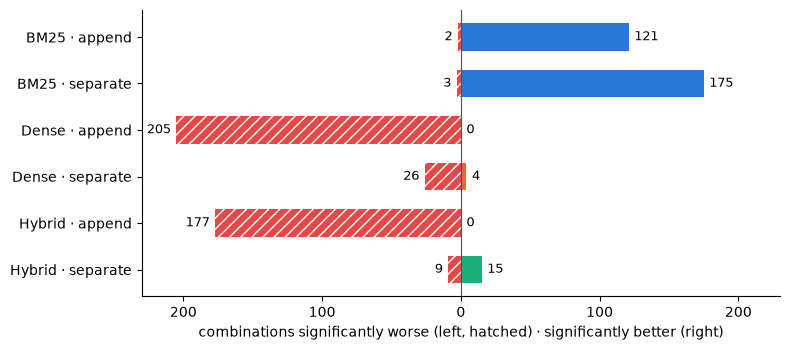

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.6))
rows = [(s, m) for s in ("bm25", "dense", "hybrid") for m in ("append", "separate")]
for y, (system, mode) in enumerate(rows):
    part = grid[(grid.system == system) & (grid["mode"] == mode)]
    up, down = better(part).sum(), worse(part).sum()
    colour = SYSTEM_COLOURS[system]
    ax.barh(y, up, color=colour, height=0.6)
    ax.barh(y, -down, color="#e34948", height=0.6, hatch="///", edgecolor="white", linewidth=0)
    ax.text(up + 4, y, str(up), va="center", fontsize=9)
    ax.text(-down - 4, y, str(down), va="center", ha="right", fontsize=9)
ax.set_yticks(range(len(rows)), [f"{SYSTEM_NAMES[s]} · {m}" for s, m in rows])
ax.axvline(0, color="#52514e", linewidth=0.8)
ax.set_xlim(-230, 230)
ax.set_xticks([-200, -100, 0, 100, 200], ["200", "100", "0", "100", "200"])
ax.set_xlabel("combinations significantly worse (left, hatched) · significantly better (right)")
ax.invert_yaxis()
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

**Figure 1. Significant wins and losses, out of 255 combinations per row** (q < 0.05). **BM25 gains in both modes; appended to dense or hybrid, expansion only loses.** Separate mode is the only setting where the strong systems gain at all (dense 4, hybrid 15).

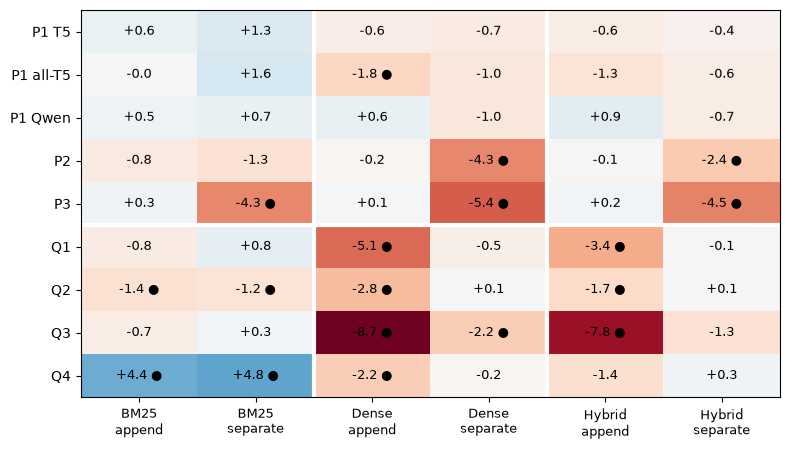

In [8]:
singles = [("products", k) for k in ("p1_t5", "p1_t5all", "p1_qwen", "p2", "p3")] + [
    ("queries", k) for k in ("q1", "q2", "q3", "q4")
]
cols = [(s, m) for s in ("bm25", "dense", "hybrid") for m in ("append", "separate")]
values = np.zeros((len(singles), len(cols)))
marks = np.zeros_like(values, dtype=bool)
for i, (side, key) in enumerate(singles):
    other = "queries" if side == "products" else "products"
    for j, (system, mode) in enumerate(cols):
        row = grid[
            (grid.system == system)
            & (grid["mode"] == mode)
            & (grid[side] == key)
            & (grid[other] == "none")
        ].iloc[0]
        values[i, j] = row["Δ nDCG@10"]
        marks[i, j] = row["q nDCG@10"] < Q_RULE
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.imshow(values, cmap="RdBu", norm=TwoSlopeNorm(0, vmin=-9, vmax=9), aspect="auto")
for i in range(len(singles)):
    for j in range(len(cols)):
        ax.text(
            j,
            i,
            f"{values[i, j]:+.1f}" + (" ●" if marks[i, j] else ""),
            ha="center",
            va="center",
            fontsize=9,
        )
ax.set_xticks(range(len(cols)), [f"{SYSTEM_NAMES[s]}\n{m}" for s, m in cols], fontsize=9)
ax.set_yticks(range(len(singles)), [NAMES[k] for _, k in singles])
ax.axhline(4.5, color="white", linewidth=3)
for j in (1.5, 3.5):
    ax.axvline(j, color="white", linewidth=3)
plt.tight_layout()
plt.show()

**Figure 2. One expansion at a time:** change in nDCG@10 (points) against the system's own unexpanded search. Blue better, red worse; **● = q < 0.05**. **Only Q4 helps, and only BM25** (+4.4 / +4.8). Appended to dense or hybrid, every query expansion loses, Q3 most (−8.7). P2 and P3 as separate lists lose 2–5 points. **Nothing alone helps the hybrid.**

In [9]:
hybrid = grid[(grid.system == "hybrid") & better(grid)].merge(
    grid_06[KEYS + ["nDCG@10", "Δ nDCG@10", "q nDCG@10"]],
    on=KEYS,
    how="left",
    suffixes=("", " 0.6B"),
)
latency = compose[compose.engine == "vllm"][KEYS + ["p99_ms"]]
hybrid = hybrid.merge(latency, on=KEYS, how="left")
recipe = pd.DataFrame(
    {
        "products": hybrid["products"].map(combo),
        "queries": hybrid["queries"].map(combo),
        "nDCG 4B": hybrid["nDCG@10"],
        "Δ 4B": hybrid["Δ nDCG@10"],
        "q 4B": hybrid["q nDCG@10"],
        "nDCG 0.6B": hybrid["nDCG@10 0.6B"],
        "Δ 0.6B": hybrid["Δ nDCG@10 0.6B"],
        "q 0.6B": hybrid["q nDCG@10 0.6B"],
        "p99 ms (0.6B, vLLM)": hybrid["p99_ms"],
    }
).sort_values("nDCG 0.6B", ascending=False)
display(
    recipe.style.hide(axis="index")
    .apply(delta_style, axis=1, delta="Δ 4B", q="q 4B")
    .apply(delta_style, axis=1, delta="Δ 0.6B", q="q 0.6B")
    .map(budget_style, subset=["p99 ms (0.6B, vLLM)"])
    .map(lambda v: f"background-color: {PRODUCT_BG}; color: #3C3489", subset=["products"])
    .map(lambda v: f"background-color: {QUERY_BG}; color: #633806", subset=["queries"])
    .format(
        {
            "nDCG 4B": "{:.3f}",
            "nDCG 0.6B": "{:.3f}",
            "Δ 4B": "{:+.1f}",
            "Δ 0.6B": "{:+.1f}",
            "q 4B": "{:.3f}",
            "q 0.6B": "{:.3f}",
            "p99 ms (0.6B, vLLM)": "{:,.0f}",
        },
        na_rep="–",
    )
)

products,queries,nDCG 4B,Δ 4B,q 4B,nDCG 0.6B,Δ 0.6B,q 0.6B,"p99 ms (0.6B, vLLM)"
P1 all-T5 + P2,Q2 + Q3 + Q4,0.791,+1.1,0.044,0.794,+1.4,0.001,501
P1 Qwen,Q2 + Q3 + Q4,0.792,+1.2,0.018,0.794,+1.4,0.000,467
P1 Qwen + P2,Q1 + Q2 + Q4,0.792,+1.2,0.028,0.792,+1.2,0.005,506
P1 Qwen + P2,Q2 + Q3 + Q4,0.791,+1.1,0.043,0.792,+1.2,0.005,501
P1 Qwen,Q1 + Q2 + Q4,0.791,+1.1,0.019,0.792,+1.2,0.002,471
P1 Qwen,Q1 + Q2 + Q3 + Q4,0.792,+1.2,0.022,0.791,+1.1,0.003,509
P1 Qwen,Q2 + Q4,0.789,+0.9,0.046,0.791,+1.1,0.005,429
P1 Qwen + P2,Q1 + Q2 + Q3 + Q4,0.791,+1.1,0.034,0.791,+1.1,0.007,543
P1 all-T5 + P3,Q1 + Q2 + Q4,0.792,+1.2,0.050,0.790,+1.0,0.026,506
P1 Qwen,Q3 + Q4,0.792,+1.2,0.014,0.790,+1.0,0.014,433


**Table 6. The 15 combinations that make the hybrid significantly better** (all separate mode), with queries expanded by Qwen3-4B and, in the size sweep, by Qwen3-0.6B. Green Δ and q: significantly better; p99 green within the 500 ms budget (searches plus 0.6B on vLLM; one combination was not timed). **Every one combines P1 with query expansion, and 14 of 15 include Q4.**

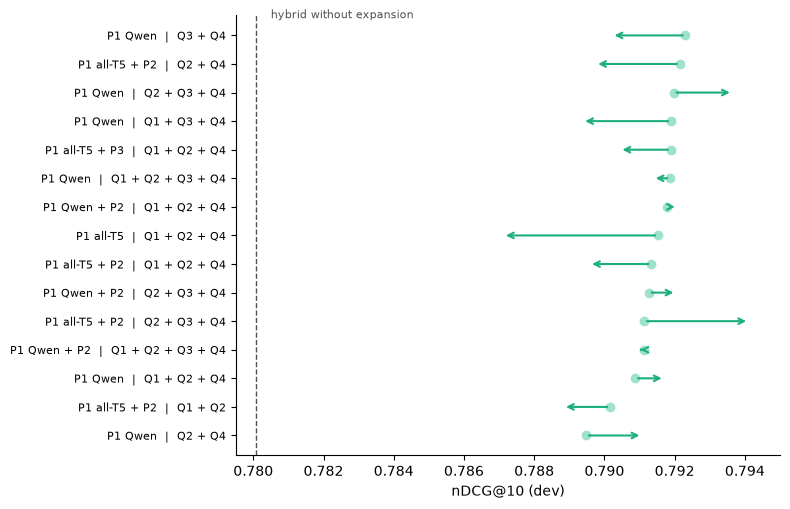

In [10]:
fig, ax = plt.subplots(figsize=(8, 5.2))
order = recipe.sort_values("nDCG 4B").reset_index(drop=True)
for y, row in order.iterrows():
    ax.annotate(
        "",
        xy=(row["nDCG 0.6B"], y),
        xytext=(row["nDCG 4B"], y),
        arrowprops={"arrowstyle": "->", "color": "#1baf7a", "lw": 1.5},
    )
    ax.plot(row["nDCG 4B"], y, "o", color="#9FE1CB", markersize=6)
ax.axvline(
    grid["base nDCG@10"][grid.system == "hybrid"].iloc[0],
    color="#52514e",
    linestyle="--",
    linewidth=1,
)
ax.text(0.7805, len(order) - 0.4, "hybrid without expansion", fontsize=8, color="#52514e")
ax.set_yticks(
    range(len(order)),
    [f"{p}  |  {q}" for p, q in zip(order["products"], order["queries"], strict=True)],
    fontsize=8,
)
ax.set_xlim(0.7795, 0.795)
ax.set_xlabel("nDCG@10 (dev)")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

**Figure 3. From Qwen3-4B to Qwen3-0.6B query expansion,** per hybrid combination: light dot 4B, arrow head 0.6B. **The 7× smaller model keeps the gain** (mean −0.06 points; 14 of 15 still q < 0.05).

## 4. Cost: which combinations are viable

In [11]:
llm = {
    engine: pd.read_parquet(RUNS_DIR / "latency_expansion" / f"llm_qwen3_0.6b_{engine}.parquet")
    for engine in ("transformers", "vllm")
}
llm_table = pd.DataFrame(
    {
        (engine, stat): llm[engine].groupby("version")["ms"].quantile(p)
        for engine in ("transformers", "vllm")
        for stat, p in (("p50", 0.5), ("p99", 0.99))
    }
).reindex(["q1", "q2", "q3", "q4", "q1+q2+q3+q4"])
llm_table.index = ["Q1", "Q2", "Q3", "Q4", "all four sent at once"]
display(
    llm_table.style.format("{:,.0f}", na_rep="–").map(
        lambda v: (
            ""
            if pd.isna(v)
            else f"background-color: {GREEN if v <= 300 else (RED if v > BUDGET_MS else GREY)}"
        )
    )
)

**Table 7. Live LLM time per query, Qwen3-0.6B,** one query at a time on the quiet tower (ms; 241 dev queries). Green ≤ 300 ms, red over the whole 500 ms budget. **The engine matters more than the model size:** the same model is 4–6× faster on vLLM, and sending all four versions at once costs barely more than one (p99 303 ms). Qwen3-4B on vLLM took 500–570 ms p50 for a single version and was stopped as too slow.

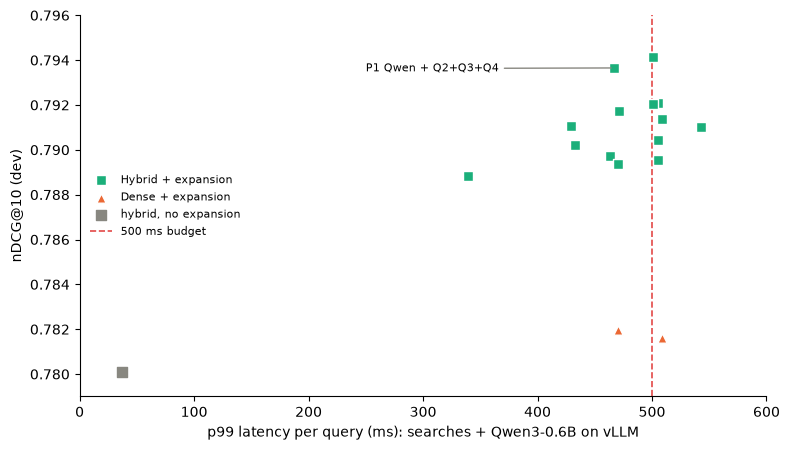

In [12]:
timed = compose[(compose.engine == "vllm") & compose.system.isin(["hybrid", "dense"])]
fig, ax = plt.subplots(figsize=(8, 4.6))
for system in ("hybrid", "dense"):
    part = timed[timed.system == system]
    ax.scatter(
        part["p99_ms"],
        part["nDCG@10"],
        marker=SYSTEM_MARKERS[system],
        color=SYSTEM_COLOURS[system],
        s=46,
        edgecolor="white",
        label=f"{SYSTEM_NAMES[system]} + expansion",
        zorder=3,
    )
ax.scatter(
    [FIRST_STAGE_MS],
    [grid["base nDCG@10"][grid.system == "hybrid"].iloc[0]],
    marker="s",
    color="#888780",
    s=50,
    label="hybrid, no expansion",
    zorder=3,
)
ax.axvline(BUDGET_MS, color="#e34948", linestyle="--", linewidth=1.2, label="500 ms budget")
best = timed[(timed[KEYS] == pd.Series(BEST, index=KEYS)).all(axis=1)].iloc[0]
ax.annotate(
    "P1 Qwen + Q2+Q3+Q4",
    (best["p99_ms"], best["nDCG@10"]),
    xytext=(250, 0.7935),
    fontsize=8,
    arrowprops={"arrowstyle": "-", "color": "#888780"},
)
ax.set_xlim(0, 600)
ax.set_xlabel("p99 latency per query (ms): searches + Qwen3-0.6B on vLLM")
ax.set_ylabel("nDCG@10 (dev)")
ax.set_ylim(0.779, 0.796)
ax.legend(fontsize=8, loc="center left", frameon=False)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

**Figure 4. Quality against live latency** for every significantly better dense and hybrid combination (0.6B query model on vLLM). **Seven hybrid combinations fit the budget; all gain +0.9 to +1.4 points for 340–470 ms, against 37 ms without expansion.** Latency per query adds the timed pieces in the order they must run: with Q4, search → LLM → search; BM25 on the CPU alongside the dense models on the GPU.

## 5. Why some expansions work

Four claims, each with a check on data we already have.

### 5.1 P1 fills the vocabulary gap

In [13]:
bm25_config = load_bm25_config(REPO_DIR / "configs/bm25_default.yaml")[1]
texts = product_texts(data.products, bm25_config.fields)


def words(strings: list[str]) -> list[set[str]]:
    return [
        set(t)
        for t in tokenize(
            strings, bm25_config.stemming, bm25_config.stopwords, bm25_config.min_word_length
        )
    ]


query_words = dict(zip(dev, words([raw_queries[q] for q in dev]), strict=True))
pairs = [(q, p, g) for q in dev for p, g in labels[q].items() if g in (0, 2)]
needed = sorted({p for _, p, _ in pairs})
product_words = {"original": dict(zip(needed, words([texts[p] for p in needed]), strict=True))}
for key in ("p1_t5", "p1_t5all", "p1_qwen", "p2", "p3"):
    extra = load_source(SOURCES[key])[1]
    added = dict(zip(needed, words([extra.get(p, "") for p in needed]), strict=True))
    product_words[f"+ {NAMES[key]}"] = {p: product_words["original"][p] | added[p] for p in needed}


def coverage(variant: str, grade: int) -> tuple[float, float]:
    """Mean share of query words found in the product, and share of pairs with all found."""
    shares = [
        len(query_words[q] & product_words[variant][p]) / len(query_words[q])
        for q, p, g in pairs
        if g == grade and query_words[q]
    ]
    return float(np.mean(shares)), float(np.mean([s == 1 for s in shares]))


gap = pd.DataFrame(
    {
        variant: {
            "Exact: words found": coverage(variant, 2)[0],
            "Exact: all words found": coverage(variant, 2)[1],
            "Irrelevant: words found": coverage(variant, 0)[0],
        }
        for variant in product_words
    }
).T
gap["gap (Exact − Irrelevant)"] = gap["Exact: words found"] - gap["Irrelevant: words found"]
display(
    gap.style.format("{:.0%}")
    .background_gradient(cmap="Purples", subset=["Exact: words found", "Exact: all words found"])
    .background_gradient(cmap="Reds", subset=["Irrelevant: words found"])
)

,Exact: words found,Exact: all words found,Irrelevant: words found,gap (Exact − Irrelevant)
original,82%,59%,49%,32%
+ P1 T5,82%,61%,50%,33%
+ P1 all-T5,82%,60%,50%,33%
+ P1 Qwen,83%,61%,50%,33%
+ P2,84%,64%,50%,34%
+ P3,82%,59%,49%,32%


**Table 8. How many of the shopper's words a product contains,** for every labelled (query, product) pair in dev: products graded Exact and products graded Irrelevant. *Words found*: share of the query's words (stemmed, as BM25 sees them) present in the product text, before and after adding each expansion. *Gap*: how much more often the words land on right products than on wrong ones. **Not supported: on WANDS the vocabulary gap is small.** Exact products already contain 82% of the shopper's words (59% contain all of them). P1 adds at most one point, P2 two, and the same words also reach Irrelevant products. P1 does not help by giving the right products missing words.

### 5.2 Q4 works because it is grounded

In [14]:
catalogue = set().union(*words(list(texts.values())))
exact = {q: [p for p, g in labels[q].items() if g == 2] for q in dev}
exact_words = {
    q: set().union(*(product_words["original"].get(p, set()) for p in exact[q]))
    if exact[q]
    else set()
    for q in dev
}
grounding = {}
for size in ("4b", "0.6b"):
    for v in ("q1", "q2", "q3", "q4"):
        expansion = load_source(f"expand_{v}_qwen3_{size}")[1]
        new = dict(zip(dev, words([expansion.get(q, "") for q in dev]), strict=True))
        new = {q: new[q] - query_words[q] for q in dev if exact[q]}
        found = [len(new[q] & exact_words[q]) / len(new[q]) for q in new if new[q]]
        known = [len(new[q] & catalogue) / len(new[q]) for q in new if new[q]]
        grounding[(f"Qwen3-{size.upper()}", NAMES[v])] = {
            "new words per query": np.mean([len(w) for w in new.values()]),
            "in the catalogue": np.mean(known),
            "in this query's Exact products": np.mean(found),
        }
grounding = pd.DataFrame(grounding).T
display(
    grounding.style.format(
        {
            "new words per query": "{:.1f}",
            "in the catalogue": "{:.0%}",
            "in this query's Exact products": "{:.0%}",
        }
    ).background_gradient(cmap="Greens", subset=["in this query's Exact products"])
)

**Table 9. Where the words an expansion adds come from.** *New words*: words not already in the query. *In the catalogue*: share that appear anywhere in the 43k product texts. *In this query's Exact products*: share that appear in at least one product graded Exact for that query, i.e. words that can pull the right products up. **Supported.** Every version uses real catalogue words (87–100%), but **Q4's new words are the most often found in the right products: 79% with Qwen3-4B against 59–69% for Q1–Q3**, and 70% against 57–64% with 0.6B. Reading the top 5 first steers the model to the words the right products use. Q3 adds the most words (18 per query with 4B), most of them generic.

### 5.3 Appending dilutes the dense query

In [15]:
arctic = DenseRetriever(load_dense_config(REPO_DIR / "configs/dense_arctic_m.yaml")[1])
base_arctic = ndcg(load_results(RUNS_DIR / BASE_RUNS["arcticm"] / "results.parquet"))
plain = arctic.encode_queries([raw_queries[q] for q in dev])
dilution, points = {}, []
for v in ("q1", "q2", "q3", "q4"):
    expansion = load_source(f"expand_{v}_qwen3_4b")[1]
    kept = [q for q in dev if expansion.get(q)]
    blended = arctic.encode_queries(
        [appended_query(raw_queries[q], [expansion[q]], 1) for q in kept]
    )
    similarity = (plain[[dev.index(q) for q in kept]] * blended).sum(dim=1).cpu().numpy()
    appended = ndcg(load_results(APPEND_DIR / GRID_4B / f"none__{v}__arcticm" / "results.parquet"))
    change = (appended - base_arctic).loc[kept].to_numpy() * 100
    points += list(zip(similarity, change, strict=True))
    dilution[NAMES[v]] = {
        "similarity to the raw query": similarity.mean(),
        "Δ nDCG@10, arctic-m appended": change.mean(),
    }
dilution = pd.DataFrame(dilution).T
similarities, changes = (np.array(column) for column in zip(*points, strict=True))
rho, rho_p = spearmanr(similarities, changes)
display(
    dilution.style.format(
        {
            "similarity to the raw query": "{:.2f}",
            "Δ nDCG@10, arctic-m appended": lambda v: f"{v:+.1f}".translate(MINUS),
        }
    ).background_gradient(cmap="RdBu", subset=["Δ nDCG@10, arctic-m appended"], vmin=-10, vmax=10)
)
print(f"Spearman ρ(similarity, Δ nDCG) per query = {rho:.2f}, p = {rho_p:.1g}, n = {len(points)}")

,similarity to the raw query,"Δ nDCG@10, arctic-m appended"
Q1,0.81,−4.3
Q2,0.86,−2.7
Q3,0.76,−7.7
Q4,0.76,−0.9


Spearman ρ(similarity, Δ nDCG) per query = 0.13, p = 0.0001, n = 959


**Table 10. How far appending moves the dense query,** arctic-m alone, Qwen3-4B expansions. *Similarity*: cosine between the embedding of the raw query and of "query + expansion"; 1.00 would be unchanged. *Δ*: nDCG@10 of the appended search minus the raw search. **Partly supported.** Q3 moves the query furthest (0.76) and loses most (−7.7), but **Q4 moves it just as far (0.76) and loses only 0.9**, and across single queries the link is weak (ρ = 0.13). Moving the query is not the problem in itself; moving it with words that do not point at the right products is.

### 5.4 A weak extra list still gets a full vote

In [16]:
alone = {}
for r in ("bm25", "inf15", "arcticm"):
    column = {
        "original search": ndcg(load_results(RUNS_DIR / BASE_RUNS[r] / "results.parquet")).mean()
    }
    for key in ("p1_t5", "p1_t5all", "p1_qwen", "p2", "p3", "q1", "q2", "q3", "q4"):
        path = LISTS_DIR / f"{SOURCES[key]}__{r}" / "results.parquet"
        label = (
            f"{NAMES[key]} (generated text only)"
            if key.startswith("p")
            else f"{NAMES[key]} (query + expansion)"
        )
        column[label] = ndcg(load_results(path)).mean()
    alone[{"bm25": "BM25", "inf15": "inf-1.5B", "arcticm": "arctic-m"}[r]] = column
alone = pd.DataFrame(alone)


def versus_original(column: pd.Series) -> list[str]:
    ref = column.iloc[0]
    return ["font-weight: bold"] + [
        f"background-color: {GREEN if v >= ref else RED}" for v in column.iloc[1:]
    ]


display(alone.style.format("{:.3f}").apply(versus_original, axis=0))

,BM25,inf-1.5B,arctic-m
original search,0.691,0.759,0.750
P1 T5 (generated text only),0.669,0.719,0.716
P1 all-T5 (generated text only),0.675,0.724,0.716
P1 Qwen (generated text only),0.674,0.723,0.735
P2 (generated text only),0.592,0.661,0.644
P3 (generated text only),0.518,0.618,0.586
Q1 (query + expansion),0.635,0.705,0.708
Q2 (query + expansion),0.601,0.715,0.708
Q3 (query + expansion),0.615,0.668,0.673
Q4 (query + expansion),0.732,0.743,0.741


**Table 11. Each separate list on its own,** nDCG@10 per retriever. Green: at least as good as the original search; red: worse. In separate mode every list gets the same RRF weight as the original. **Supported.** Only Q4 on BM25 beats the original alone (0.732 against 0.691). **The lists that hurt as extra votes are the weakest alone:** P2 (0.59–0.66) and P3 (0.52–0.62). The lists in every hybrid win, P1 (0.67–0.74) and Q4 (0.73–0.74), are nearly as good as the original while built from different text, so as an extra vote they can correct some of its mistakes (reasoning, not measured).

### 5.5 Who gains

In [17]:
per_query = pd.read_parquet(RUNS_DIR / GRID_4B / "per_query.parquet")
id_column = "query_id" if "query_id" in per_query.columns else per_query.columns[0]
best_scores = per_query[(per_query[KEYS] == pd.Series(BEST, index=KEYS)).all(axis=1)].set_index(
    id_column
)["nDCG@10"]
base_hybrid = ndcg(base_lists("hybrid"))
change = (best_scores - base_hybrid).loc[dev] * 100
n_exact = pd.Series({q: len(exact[q]) for q in dev})
groups = pd.DataFrame(
    {
        "Exact matches": n_exact.map(difficulty_bucket),
        "query words": pd.Series({q: min(len(raw_queries[q].split()), 4) for q in dev}).map(
            lambda n: "4+" if n == 4 else str(n)
        ),
        "change": change,
    }
)
who = pd.concat(
    [
        groups.groupby(column)["change"]
        .agg(
            queries="size",
            mean_change="mean",
            improved=lambda s: (s > 0).mean(),
            worse=lambda s: (s < 0).mean(),
        )
        .assign(by=column)
        .set_index("by", append=True)
        .swaplevel()
        for column in ("Exact matches", "query words")
    ]
)
who = who.rename(columns={"mean_change": "mean change"}).rename_axis([None, None])
display(
    who.style.format(
        {
            "mean change": lambda v: f"{v:+.1f}".translate(MINUS),
            "improved": "{:.0%}",
            "worse": "{:.0%}",
        }
    ).background_gradient(cmap="RdBu", subset=["mean change"], vmin=-5, vmax=5)
)

**Table 12. Which queries gain from the best combination** (P1 Qwen + Q2+Q3+Q4, separate, hybrid, 4B), per-query nDCG@10 change in points against the unexpanded hybrid. Grouped by how many Exact matches a query has (a proxy for difficulty) and by query length. **The gain is broad, small and two-sided:** in every group but one-word queries, 26–46% of queries improve and 17–27% get worse. Queries with over 100 Exact matches gain most (+3.1, 37 queries); one-word queries do not gain (12 queries). No group of hard queries is rescued: the +1.2 is many small shifts.

| Claim | Verdict | Evidence |
|---|---|---|
| P1 fills the vocabulary gap | ✗ not supported | Exact products already hold 82% of the query's words; P1 adds ≤ 1 point |
| Q4 works because it is grounded | ✓ supported | 79% of Q4's new words occur in the right products, against 59–69% for Q1–Q3 |
| Appending dilutes the dense query | ~ partly | Q3 moved the query far and lost 7.7; Q4 moved it as far and lost 0.9 |
| A weak extra list still gets a full vote | ✓ supported | P2/P3 lists alone 0.52–0.66 and they hurt; P1/Q4 lists 0.67–0.74 and they help |

**Table 13. The four claims.** ✓ supported, ~ partly, ✗ not supported.

**So why does P1 + Q4 as separate lists work?** Not by filling missing words, but by adding **second opinions**: two rankings nearly as good as the original, built from different text (shopper-style searches written for each product, and catalogue words picked after seeing the top results). RRF rewards products that several good lists agree on. **Appending** has no such safeguard: the expansion is blended into the one text or the one vector, so its noise changes the only ranking there is, which is why it hurts dense models. **P2, P3 and Q1–Q3** fail because their lists are too weak on their own or their words are generic.

## 6. Conclusion

| | Result |
|---|---|
| **Works** | P1 (any generator, Qwen best) + query expansion with Q4, both as separate lists: hybrid 0.789–0.792 with Qwen3-4B queries, up to 0.794 with 0.6B (+0.9 to +1.4, q < 0.05) |
| **Does not work** | Appending to dense or hybrid; P2, P3 or Q1–Q3 on their own; anything without P1 for the hybrid |
| **Query model** | Qwen3-0.6B is enough (keeps 14 of 15 hybrid gains); 4B is too slow live |
| **Viable in 500 ms** | 7 combinations; best **P1 Qwen + Q2+Q3+Q4: 0.794, p99 467 ms**; cheaper P1 Qwen + Q2+Q4: 0.791, 429 ms |
| **Price** | 37 ms → 340–470 ms p99 for +0.9 to +1.4 nDCG@10 |

**Decision:** whether +1.4 points is worth 12× the latency. Before deciding:
- **Shared GPU:** the latency pieces were timed one at a time. vLLM, inf-1.5B and arctic-m must fit on one 12 GB GPU together and be timed together.
- **Lighter extra votes:** every list has the same RRF weight; giving the extra lists less weight might keep the gain and cut the risk.
- **Known flaw:** Q2 keeps the filler word *unspecified* (the cleaning step drops *unknown* and *N/A* only).

**Caveats.** Dev queries only; the test set is used once, at the end. Q4 shows the model the hybrid's own top 5, for every system. Latency is for one user at a time.